# 06 ANN手机价格分类实战与CNN卷积池化


本篇对应 **day06**，是「06-深度学习神经网络」7篇笔记中的第6篇。承接05的数据准备、优化器和训练模式，完成手机价格分类的ANN训练、测试与调优流程，再学习图像基础、卷积层和池化层。

资料：[深度学习神经网络课程资料](https://pan.baidu.com/s/1FPhKS2qMBgnqVOXCyhBTog?pwd=1234)，提取码 `1234`。已核对 `04_深度学习神经网络/视频/day06` 的 **17个视频文件标题**。原教师 `课堂笔记.zip`、`课件.zip`、课程代码与手机原始数据正文未取得，视频未逐段转录；本文按目录组织，文字、示例、数据和图均独立编写。

本篇全部为Markdown单元，Python代码块按顺序放入代码单元即可运行；图片直接内嵌Notebook附件。人工手机数据用于验证流程，不代表真实手机价格规律，也不代表课程原数据的字段、样本量或实验成绩。


## 本篇学习路线

| 视频范围 | 内容 | 本篇完成的工作 |
| --- | --- | --- |
| 01 | 手机价格分类数据准备回顾 | 特征、标签、划分与预处理 |
| 02-05 | ANN搭建、训练、测试、调优 | 完整训练流程、验证集选择、保存与推理 |
| 06-07 | 图像知识、上午内容回顾 | RGB像素、形状、数值范围 |
| 08 | CNN概述 | 局部连接、共享权重、特征图 |
| 09-15 | 卷积计算、填充、步长、多通道、多卷积核、尺寸和API | 手算与PyTorch结果对照 |
| 16-17 | 池化介绍与API | MaxPool、AvgPool和尺寸变化 |

这篇完成CNN基本运算，并给出可运行的网络骨架；图像分类完整案例继续放在07。


## 1. 环境与运行顺序

全部例子使用CPU。手机表格在内存生成，图像也用小数组构造，不需要下载数据文件。

```bash
python -m pip install torch numpy pandas scikit-learn pillow
```

```python
import copy
import io
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, classification_report
from PIL import Image

torch.manual_seed(2026)
torch.set_num_threads(2)
device = torch.device("cpu")
print("PyTorch:", torch.__version__, "device:", device)
```

使用固定种子方便本例复现，跨硬件或跨版本结果仍可能不同。前半部分的ANN适合二维表格，后半部分的CNN适合保留空间结构的图像，两种输入不能直接混用。


## 2. 手机分类需求：特征、标签和样本

输入是一行手机特征，输出是一个价格档位。05篇的12行小表足以讲解数据准备，但不足以评价分类能力；本篇独立生成600条人工数据，保留相同的5个演示字段，并使用 `low / mid / high` 三个类别。

类别由人工生成过程预先给定，特征围绕不同类别的中心采样。这个设置刻意让任务容易学习，用来演示训练是否正确运行；真实价格受品牌、地区、时间和市场因素影响，不能从本例推出真实定价结论。

```python
rng = np.random.default_rng(2026)
feature_columns = ["ram_gb", "storage_gb", "screen_in", "battery_mah", "camera_mp"]
classes = ["low", "mid", "high"]
class_to_index = {name: i for i, name in enumerate(classes)}
centers = np.array([
    [4, 64, 6.0, 3300, 16],
    [8, 128, 6.3, 4100, 48],
    [12, 256, 6.6, 4900, 80],
], dtype=float)
noise_scale = np.array([1.8, 35, 0.2, 450, 18])
label_index = np.repeat(np.arange(3), 200)
raw_features = centers[label_index] + rng.normal(size=(600, 5)) * noise_scale
raw_features = np.maximum(raw_features, [1, 16, 4.5, 1000, 1])
phone_df = pd.DataFrame(raw_features, columns=feature_columns)
phone_df["price_level"] = np.array(classes)[label_index]
phone_df["sample_id"] = np.arange(len(phone_df))
phone_df.loc[rng.choice(len(phone_df), size=18, replace=False), "battery_mah"] = np.nan
phone_df = phone_df.sample(frac=1, random_state=2026).reset_index(drop=True)
assert phone_df["sample_id"].is_unique
assert phone_df["price_level"].value_counts().to_dict() == {name: 200 for name in classes}
assert phone_df["battery_mah"].isna().sum() == 18
print(phone_df.head())
```

`sample_id`仅用于检查划分，不能放进特征。实际读取CSV时先核对字段、单位、目标列和缺失标签；遇到重复手机、同一用户或时间序列，还需要按实体或时间划分，不能机械照搬随机切分。


## 3. 训练、验证、测试：各自负责什么

| 数据集 | 用途 | 能否影响模型选择 |
| --- | --- | --- |
| 训练集 | 拟合填充值、标准化器、模型参数 | 可以 |
| 验证集 | 选择学习率、层数、训练轮数与最佳权重 | 可以，但反复选择也会过拟合验证集 |
| 测试集 | 模型方案固定后的最终评价 | 不用于调参 |

先留出20%测试集，再从剩余数据留出25%验证集，最终为60%/20%/20%。本例每类数量足够，采用分层划分。

```python
dev_df, test_df = train_test_split(
    phone_df, test_size=0.2, random_state=2026,
    stratify=phone_df["price_level"],
)
train_df, val_df = train_test_split(
    dev_df, test_size=0.25, random_state=2027,
    stratify=dev_df["price_level"],
)
train_ids, val_ids, test_ids = [set(frame["sample_id"]) for frame in (train_df, val_df, test_df)]
assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)
assert len(train_df) == 360 and len(val_df) == len(test_df) == 120
print("train / val / test:", len(train_df), len(val_df), len(test_df))
```

先划分再拟合预处理。标签映射来自任务预先定义的类别，不能让三个数据集各自生成一套编号。


## 4. 预处理与DataLoader：只在训练集fit

用训练集的中位数填充数值缺失值，再按训练集均值与标准差缩放。Pipeline让训练、验证和预测复用同一组参数。

```python
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
train_array = preprocessor.fit_transform(train_df[feature_columns]).astype("float32")
val_array = preprocessor.transform(val_df[feature_columns]).astype("float32")
test_array = preprocessor.transform(test_df[feature_columns]).astype("float32")

def make_dataset(frame, features):
    labels = frame["price_level"].map(class_to_index).to_numpy(dtype="int64")
    return TensorDataset(torch.from_numpy(features), torch.from_numpy(labels))

train_dataset = make_dataset(train_df, train_array)
val_dataset = make_dataset(val_df, val_array)
test_dataset = make_dataset(test_df, test_array)
loader_generator = torch.Generator().manual_seed(2026)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, generator=loader_generator)
train_eval_loader = DataLoader(train_dataset, batch_size=64, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

assert np.isfinite(train_array).all() and np.isfinite(test_array).all()
assert np.allclose(train_array.mean(axis=0), 0, atol=1e-6)
assert np.allclose(preprocessor["imputer"].statistics_, train_df[feature_columns].median())
assert np.allclose(preprocessor["scaler"].mean_, preprocessor["imputer"].transform(train_df[feature_columns]).mean(axis=0))
assert sum(len(xb) for xb, yb in train_loader) == 360
assert train_dataset.tensors[0].shape == (360, 5)
assert train_dataset.tensors[1].dtype == torch.int64
```

验证和测试无需打乱。最后一个不足32的训练batch仍保留；本例ANN不使用BatchNorm，没有单样本BN问题。若换成带BN的表格模型，要先检查最后一批大小，再决定是否仅对训练集设置 `drop_last=True`。


## 5. 搭建ANN：输出logits，不提前做Softmax

本例的结构为 `5 → 32 → 16 → 3`，隐藏层用ReLU，加入轻量Dropout演示模式切换。结构与超参数为本篇独立设置，不是课程原代码。

```python
class PhoneANN(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Dropout(p=0.1),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, num_classes),
        )

    def forward(self, x):
        return self.net(x)

torch.manual_seed(2026)
model = PhoneANN(len(feature_columns), len(classes)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=40, gamma=0.5)
assert model(torch.zeros(4, 5, device=device)).shape == (4, 3)
parameter_count = sum(p.numel() for p in model.parameters())
assert parameter_count == 771
print(model, "parameters:", parameter_count)
```

交叉熵输入的logits形状为 `(N,3)`，整数标签形状为 `(N,)`。最终层不加ReLU或Softmax：logits可以为负，`CrossEntropyLoss`已包含相应的对数归一化计算。需要展示概率时，再在推理输出上调用Softmax。


## 6. 评价函数：按样本数统计loss和准确率

模型评价要同时处理两件事：`eval()`关闭Dropout并切换BN行为，`no_grad()`关闭本次计算的梯度记录。两者不能互相替代。

```python
def evaluate(net, loader):
    was_training = net.training
    net.eval()
    total_loss, correct, count = 0.0, 0, 0
    predicted, targets = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = net(xb)
            loss = criterion(logits, yb)
            pred = logits.argmax(dim=1)
            total_loss += loss.item() * yb.size(0)
            correct += (pred == yb).sum().item()
            count += yb.size(0)
            predicted.append(pred.cpu())
            targets.append(yb.cpu())
    net.train(was_training)
    return {
        "loss": total_loss / count,
        "accuracy": correct / count,
        "pred": torch.cat(predicted).numpy(),
        "target": torch.cat(targets).numpy(),
        "samples": count,
    }

initial_train_metrics = evaluate(model, train_eval_loader)
assert model.training
assert initial_train_metrics["samples"] == len(train_dataset)
print("initial train loss:", initial_train_metrics["loss"])
```

不能把所有batch均值简单平均：最后一个batch更小时，它不应拥有和完整batch一样的权重。本函数先乘batch样本数，最后除以总样本数。空数据集需要在调用前处理，本例数据集均非空。


## 7. 完整训练：训练集更新，验证集选权重

每轮按batch清梯度、前向、计算损失、反向、更新。验证不反向传播；最佳权重按验证loss保存深拷贝。学习率在该轮训练开始时记录，scheduler在轮末更新。

```python
history = []
best_val_loss = float("inf")
best_state, best_epoch = None, None
epochs = 80
for epoch in range(1, epochs + 1):
    model.train()
    used_lr = optimizer.param_groups[0]["lr"]
    train_loss_sum, train_correct, train_count = 0.0, 0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        train_loss_sum += loss.item() * yb.size(0)
        train_correct += (logits.argmax(dim=1) == yb).sum().item()
        train_count += yb.size(0)

    val_metrics = evaluate(model, val_loader)
    if val_metrics["loss"] < best_val_loss:
        best_val_loss = val_metrics["loss"]
        best_state = copy.deepcopy(model.state_dict())
        best_epoch = epoch
    history.append({
        "epoch": epoch, "lr": used_lr,
        "train_loss": train_loss_sum / train_count,
        "train_accuracy": train_correct / train_count,
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
    })
    scheduler.step()
    if epoch == 1 or epoch % 20 == 0:
        print(epoch, history[-1])

assert best_state is not None
assert np.allclose([row["lr"] for row in history], [0.01] * 40 + [0.005] * 40)
assert all(np.isfinite(row["train_loss"]) and np.isfinite(row["val_loss"]) for row in history)
model.load_state_dict(best_state)
model.eval()
final_train_metrics = evaluate(model, train_eval_loader)
final_val_metrics = evaluate(model, val_loader)
assert final_train_metrics["loss"] < initial_train_metrics["loss"]
print("best epoch:", best_epoch, "val loss:", final_val_metrics["loss"])
```

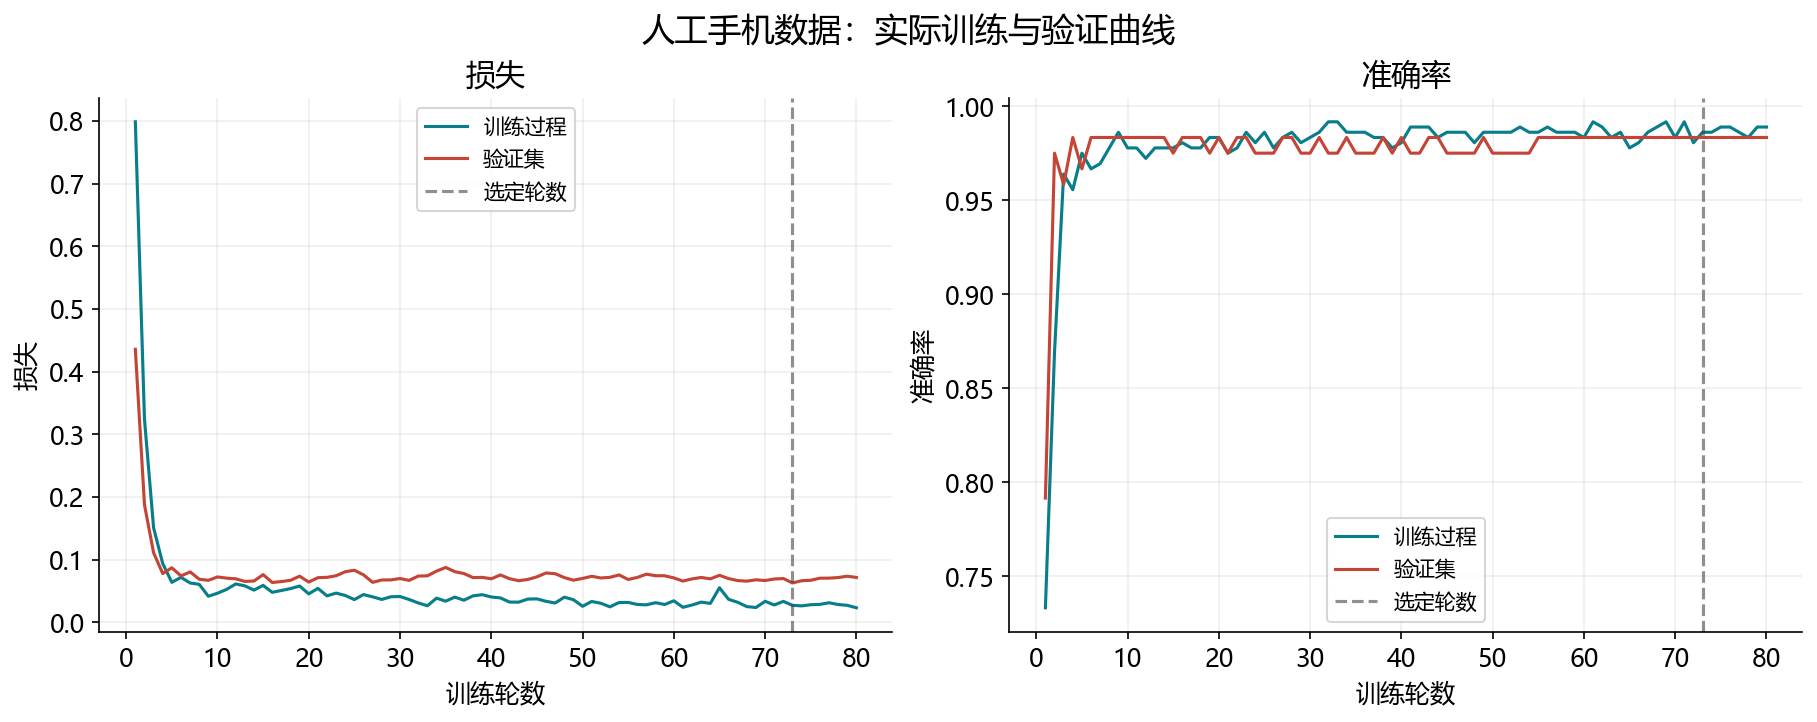

图的训练指标来自当轮训练过程中的batch，包含Dropout；验证指标来自轮末固定模型并关闭Dropout后的结果。二者的计算时刻和模式不同，不能把每一个差值都当成过拟合。验证loss回升、训练loss继续下降时，应进一步检查过拟合与数据划分。


## 8. 测试与混淆矩阵：看清错误落在哪一类

最佳权重已由验证集选定，现在才在测试集上评价。准确率只给整体比例，还应查看每类precision、recall、F1和混淆矩阵。

```python
test_metrics = evaluate(model, test_loader)
phone_confusion = confusion_matrix(
    test_metrics["target"], test_metrics["pred"], labels=np.arange(len(classes)),
)
assert phone_confusion.shape == (3, 3)
assert phone_confusion.sum() == len(test_dataset)
assert abs(np.trace(phone_confusion) / phone_confusion.sum() - test_metrics["accuracy"]) < 1e-12
print("test loss / accuracy:", test_metrics["loss"], test_metrics["accuracy"])
print(classification_report(
    test_metrics["target"], test_metrics["pred"],
    labels=np.arange(len(classes)), target_names=classes, zero_division=0,
))
```

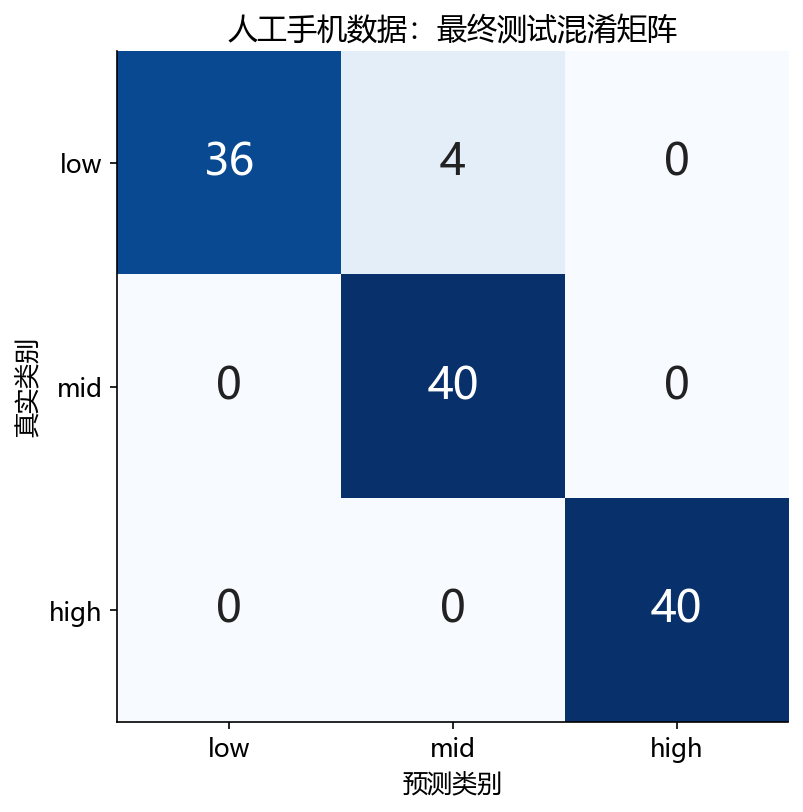

横轴为预测类别，纵轴为真实类别；对角线为正确分类，非对角线显示混淆。类别不均衡时只看准确率容易掩盖少数类问题，可结合macro-F1与每类召回率。

本次CPU验证：训练/验证/测试样本为360/120/120，按验证loss选择第73轮权重；初始训练loss为1.1079，加载最佳权重后的训练loss为0.0251，验证准确率为98.33%，最终测试准确率为96.67%。更换版本或环境后具体数值可能变化。

这些数值只用于证明本篇人工数据上的代码流程可运行，不能作为真实数据效果或课程成绩。


## 9. 保存与加载：模型要和预处理一起交付

只保存权重无法解释输入列顺序，也无法重新得到训练时的填充值与缩放。推理至少需要结构配置、权重、特征顺序、类别映射和预处理参数。

下面将数据写入内存缓冲区模拟文件保存，不产生额外模型文件。换成路径即可使用 `torch.save(checkpoint, "phone_ann.pt")`；这里只加载自己生成的状态，显式使用 `weights_only=True`。

```python
checkpoint = {
    "model_state": copy.deepcopy(model.state_dict()),
    "input_dim": len(feature_columns), "num_classes": len(classes),
    "feature_columns": feature_columns, "classes": classes,
    "fill_values": torch.tensor(preprocessor["imputer"].statistics_, dtype=torch.float64),
    "mean": torch.tensor(preprocessor["scaler"].mean_, dtype=torch.float64),
    "scale": torch.tensor(preprocessor["scaler"].scale_, dtype=torch.float64),
    "best_epoch": best_epoch,
}
memory_file = io.BytesIO()
torch.save(checkpoint, memory_file)
memory_file.seek(0)
loaded = torch.load(memory_file, map_location=device, weights_only=True)
loaded_model = PhoneANN(loaded["input_dim"], loaded["num_classes"]).to(device)
loaded_model.load_state_dict(loaded["model_state"])
loaded_model.eval()
assert all(torch.equal(value, loaded_model.state_dict()[name]) for name, value in model.state_dict().items())
```

这里保存的是推理状态。继续训练还需优化器、scheduler、轮数和必要的随机状态；05篇已讨论训练状态恢复。保存到文件时同时记录依赖版本和模型定义，避免只有一份无法解释的权重。


## 10. 单条预测：复用训练时的列顺序与统计量

```python
def predict_phone(frame, restored_model, state):
    raw = frame[state["feature_columns"]].to_numpy(dtype=np.float64)
    filled = np.where(np.isnan(raw), state["fill_values"].numpy(), raw)
    scaled = ((filled - state["mean"].numpy()) / state["scale"].numpy()).astype("float32")
    if not np.isfinite(scaled).all():
        raise ValueError("phone features must be finite after preprocessing")
    restored_model.eval()
    with torch.no_grad():
        logits = restored_model(torch.from_numpy(scaled).to(device))
        probabilities = logits.softmax(dim=1).cpu().numpy()
    indices = probabilities.argmax(axis=1)
    names = [state["classes"][int(i)] for i in indices]
    return names, probabilities

example_phone = pd.DataFrame([{
    "ram_gb": 8, "storage_gb": 128, "screen_in": 6.3,
    "battery_mah": np.nan, "camera_mp": 48,
}])
predicted_names, predicted_probabilities = predict_phone(example_phone, loaded_model, loaded)
assert predicted_probabilities.shape == (1, 3)
assert np.allclose(predicted_probabilities.sum(axis=1), 1)

# 用本例测试输入核对：保存后的预处理应复现Pipeline结果
restored_names, restored_probabilities = predict_phone(test_df, loaded_model, loaded)
with torch.no_grad():
    reference_probabilities = model(torch.from_numpy(test_array).to(device)).softmax(dim=1).cpu().numpy()
assert np.allclose(restored_probabilities, reference_probabilities, atol=1e-6)
print(predicted_names, predicted_probabilities)
```

Softmax输出总和为1，但不天然等于可靠的置信度；真实部署还应关注概率校准与分布变化。缺列应明确报错，新增无关列可按特征清单忽略，不能把任意CSV列顺序当成模型输入顺序。


## 11. 调优：先确定问题在哪一层

| 现象 | 优先排查 | 可尝试的调整 |
| --- | --- | --- |
| train与val都学不好 | 标签、输入尺度、loss、学习率 | 修正数据流程；调整学习率和容量 |
| train好、val差 | 划分、泄漏、过拟合、分布差异 | 简化模型、正则化、更多数据 |
| loss变NaN或剧烈震荡 | 非有限输入、学习率过大 | 检查数据与梯度，降低lr |
| 训练正常、加载后异常 | 特征顺序、预处理、模式、权重 | 验证同一输入的输出一致性 |
| 准确率高但某类几乎不被识别 | 类别分布、混淆矩阵 | 看每类召回率；合理采样或加权 |

先建立简单基线，再一次只改少量因素，并记录验证集表现。学习率、层宽、Dropout概率、训练轮数都在训练/验证数据内选择。不要看测试结果反复挑最佳模型；测试集被用于选择后，就不再是独立的最终评价。

本例的80轮与网络宽度是演示设置，没有进行系统搜索。早停可以减少无效训练，但应按验证指标实施；学习率衰减也不是越快越好。


## 12. 图像基础：一张图也是数值数组

灰度图通常可表示为 `(H,W)`，RGB图常见为 `(H,W,3)`。8位图像像素范围通常是0-255；3个通道分别表示R、G、B。分辨率、通道数和数值范围是不同概念。

```python
rgb_array = np.array([
    [[255, 0, 0], [255, 128, 0], [0, 255, 0], [0, 0, 255]],
    [[255, 255, 255], [128, 128, 128], [0, 0, 0], [255, 255, 0]],
    [[0, 255, 255], [255, 0, 255], [64, 128, 192], [192, 128, 64]],
    [[255, 64, 64], [64, 255, 64], [64, 64, 255], [200, 200, 200]],
], dtype=np.uint8)
image = Image.fromarray(rgb_array)
assert image.mode == "RGB" and image.size == (4, 4)
gray_array = image.convert("L")
assert np.asarray(gray_array).shape == (4, 4)
print("array shape:", rgb_array.shape, "PIL size:", image.size)
```

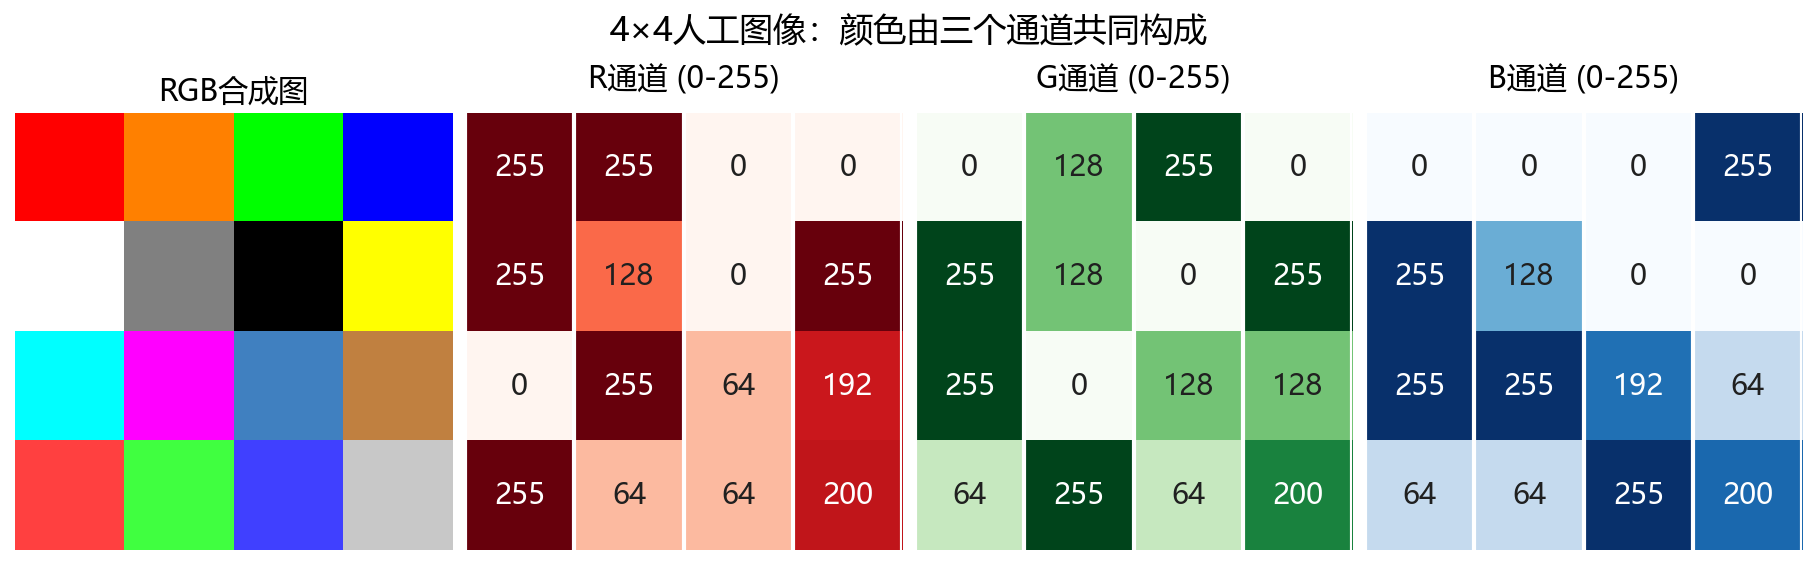

PIL的 `size` 为 `(宽,高)`，数组的shape为 `(高,宽,通道)`。常见OpenCV读图顺序是BGR，与RGB不同；调换通道会改变颜色。灰度化是通道的加权变换，不能简单删除G、B就称为标准灰度图。


## 13. 从HWC到NCHW：Conv2d的常用输入约定

PyTorch批量二维卷积一般输入为 `(N,C,H,W)`：batch、通道、高、宽。不能只用reshape把HWC改成CHW，因为reshape不会把原来的通道轴移到前面。

```python
image_tensor = torch.from_numpy(rgb_array.copy()).permute(2, 0, 1).contiguous()
image_tensor = image_tensor.to(torch.float32) / 255.0
image_batch = image_tensor.unsqueeze(0)
assert image_batch.shape == (1, 3, 4, 4)
assert image_batch.dtype == torch.float32
assert 0 <= image_batch.min() and image_batch.max() <= 1
assert torch.equal(image_batch[0, :, 0, 0], torch.tensor([1.0, 0.0, 0.0]))
round_trip = (image_batch[0].permute(1, 2, 0).numpy() * 255).round().astype(np.uint8)
assert np.array_equal(round_trip, rgb_array)
```

除以255只把范围缩放到0-1，不是按数据集均值和标准差标准化。训练与推理应使用相同的颜色模式、尺寸和归一化参数。随机裁剪等数据增强通常用于训练，验证和测试使用可复现的变换。


## 14. CNN概述：局部连接与共享权重

全连接层把输入展平，每个输出可以连接所有输入；卷积在空间上扫描局部窗口，同一个卷积核在不同位置复用。这样保留空间组织，并减少相同空间任务中的参数量。

一个卷积核响应某些局部模式，输出称为特征图。多个输出通道可以学习不同模式；模型训练得到的卷积核不一定就是可直接解释的“边缘检测器”。

卷积并不保证对任意平移都不变：在理想设置下具有平移等变性质，但边界、stride和采样会影响它。池化也只是汇总局部信息，不能保证所有变化都被消除。

典型分类流程：`图像 → 卷积/ReLU → 池化 → 更多特征层 → 分类头 → logits`。CNN仍然需要损失函数、优化器、训练/评价模式与规范的数据划分。


## 15. 单通道卷积：窗口内逐元素相乘再相加

本例输入为4×4，核为2×2，stride=1、padding=0。第一个输出值为：

$$1\times1+2\times0+5\times0+6\times2=13.$$

深度学习接口中常说的卷积实际按互相关方式计算：下面不翻转卷积核。与数学中要求翻转核的严格卷积定义要区分。

```python
conv_input = torch.arange(1, 17, dtype=torch.float32).reshape(1, 1, 4, 4)
conv_kernel = torch.tensor([[[[1.0, 0.0], [0.0, 2.0]]]])
conv_output = F.conv2d(conv_input, conv_kernel)
conv_manual = torch.empty(3, 3)
for row in range(3):
    for col in range(3):
        window = conv_input[0, 0, row:row + 2, col:col + 2]
        conv_manual[row, col] = (window * conv_kernel[0, 0]).sum()
conv_expected = torch.tensor([[13., 16., 19.], [25., 28., 31.], [37., 40., 43.]])
assert conv_output.shape == (1, 1, 3, 3)
assert torch.equal(conv_manual, conv_expected)
assert torch.equal(conv_output[0, 0], conv_expected)
print(conv_output)
```

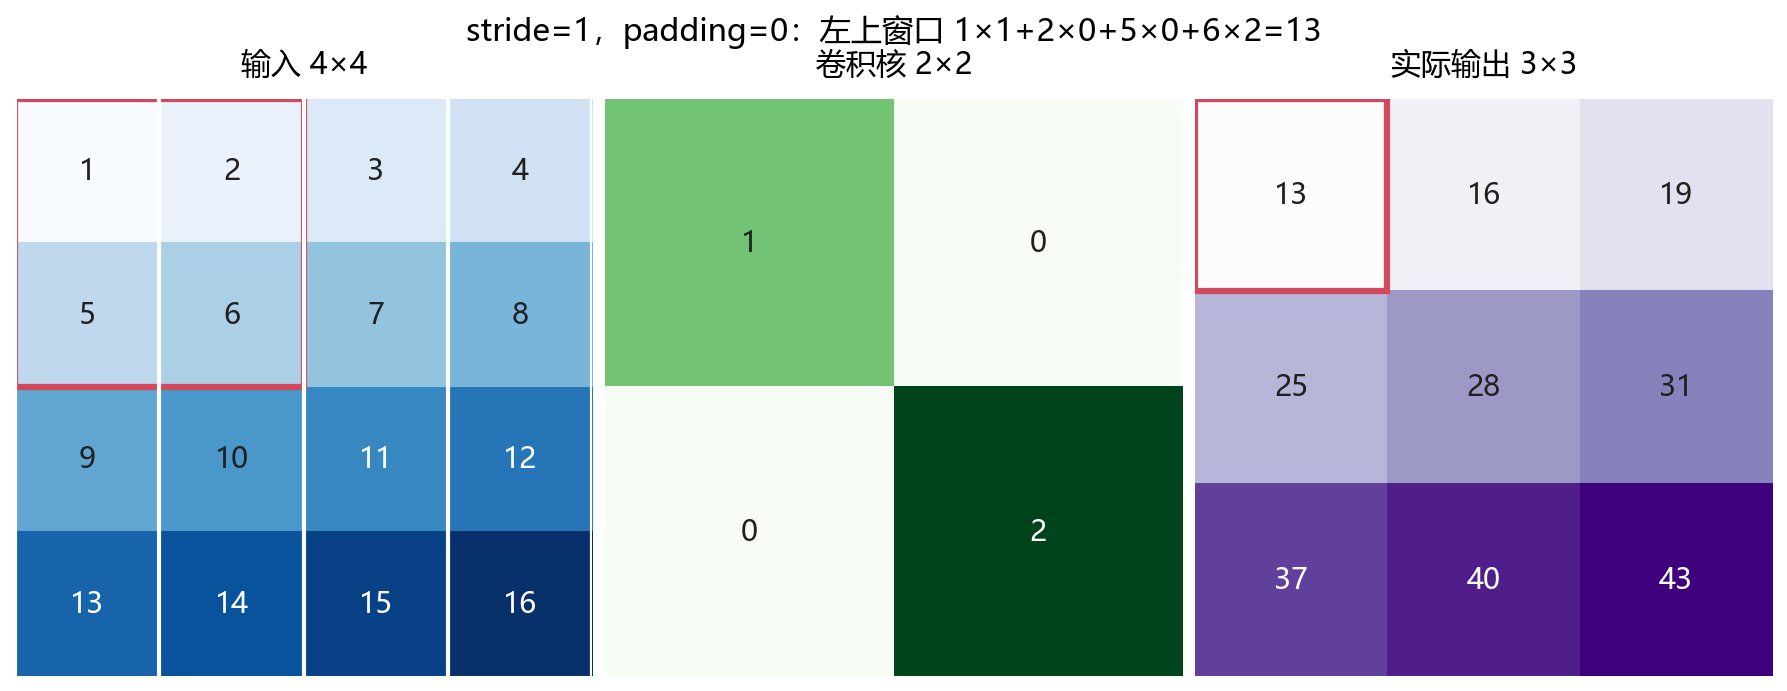

核可以包含负数，特征图也可以为负；卷积不是先取最大值。偏置若存在，在每个输出通道的各空间位置加上同一个该通道偏置。


## 16. Padding与Stride：边界怎么处理，窗口走几格

Padding在边界补充元素，常见零填充；Stride决定相邻窗口起点的间隔。stride越大，通常输出越小。填充还影响边界数值，不只影响尺寸。

```python
ones_kernel = torch.ones(1, 1, 3, 3)
valid_output = F.conv2d(conv_input, ones_kernel, padding=0, stride=1)
padded_output = F.conv2d(conv_input, ones_kernel, padding=1, stride=1)
strided_output = F.conv2d(conv_input, ones_kernel, padding=1, stride=2)
assert valid_output.shape == (1, 1, 2, 2)
assert padded_output.shape == (1, 1, 4, 4)
assert strided_output.shape == (1, 1, 2, 2)
assert padded_output[0, 0, 0, 0].item() == 14
assert torch.equal(strided_output, padded_output[:, :, ::2, ::2])
```

左上角的padding窗口包含0和原图的1、2、5、6，因此和为14。不要把padding理解成复制边缘；`nn.Conv2d`默认零填充，其他 `padding_mode` 有不同边界规则。


## 17. 特征图尺寸：分别计算高与宽

对称整数padding、普通二维卷积的单个空间维度：

$$O=\left\lfloor\frac{I+2P-D(K-1)-1}{S}+1\right\rfloor.$$

I为输入尺寸、K为核大小、P为两侧各自的填充量、S为stride、D为dilation。有效核跨度为 `D(K-1)+1`；不整除时向下取整，不是四舍五入。

```python
def output_size(size, kernel, padding=0, stride=1, dilation=1):
    return (size + 2 * padding - dilation * (kernel - 1) - 1) // stride + 1

assert output_size(4, 3, padding=1, stride=2) == 2
assert output_size(32, 3, padding=1) == 32
assert output_size(7, 3, dilation=2) == 3
dilated_output = F.conv2d(torch.ones(1, 1, 7, 7), ones_kernel, dilation=2)
assert dilated_output.shape[-2:] == (3, 3)

rect_conv = nn.Conv2d(3, 6, kernel_size=(3, 5), stride=(2, 1), padding=(1, 2))
rect_output = rect_conv(torch.zeros(2, 3, 11, 13))
assert rect_output.shape == (2, 6, output_size(11, 3, 1, 2), output_size(13, 5, 2, 1))
assert rect_output.shape == (2, 6, 6, 13)
```

输出通道数由 `out_channels`指定，高宽由核、padding、stride和dilation共同决定。奇数核、dilation=1、stride=1时，取P=(K-1)/2可以保持高宽；不能无条件把padding=1等同于“尺寸不变”。

PyTorch `padding="same"` 有接口约束，例如普通Conv2d不支持在这个模式下使用大于1的stride；上述公式用于本篇显式整数padding设置。


## 18. 多输入通道：每个输出通道要汇总所有输入通道

groups=1时，一个输出通道对应一组形状为 `(C_in,K_H,K_W)` 的权重。先分别与各输入通道做空间计算，再把这些结果相加，最后加一个偏置。

$$Y_{o,h,w}=b_o+\sum_{c=1}^{C_{in}}\sum_{i,j}W_{o,c,i,j}X_{c,h+i,w+j}.$$

公式为stride=1、无padding、dilation=1的简化写法，实际索引由卷积配置决定。

```python
two_channel_input = torch.cat([conv_input, 2 * conv_input], dim=1)
two_channel_kernel = torch.cat([
    torch.ones(1, 1, 2, 2),
    0.5 * torch.ones(1, 1, 2, 2),
], dim=1)
multi_channel_output = F.conv2d(two_channel_input, two_channel_kernel)
separate_sum = (
    F.conv2d(two_channel_input[:, 0:1], two_channel_kernel[:, 0:1])
    + F.conv2d(two_channel_input[:, 1:2], two_channel_kernel[:, 1:2])
)
assert two_channel_kernel.shape == (1, 2, 2, 2)
assert multi_channel_output.shape == (1, 1, 3, 3)
assert torch.equal(multi_channel_output, separate_sum)
assert multi_channel_output[0, 0, 0, 0].item() == 28
```

RGB有3个输入通道，不代表输出必须有3个通道。一个输出核会汇总所有输入通道；这里2个输入通道最后仍可得到1个输出通道。


## 19. 多卷积核与参数量：out_channels决定特征图数量

多个输出核各自生成一张特征图，组合成多个输出通道。groups=1、有偏置时：

$$\text{参数量}=C_{out}(C_{in}K_HK_W+1).$$

```python
two_output_kernels = torch.cat([two_channel_kernel, -two_channel_kernel], dim=0)
two_output_maps = F.conv2d(two_channel_input, two_output_kernels)
assert two_output_maps.shape == (1, 2, 3, 3)
assert torch.equal(two_output_maps[:, 0], -two_output_maps[:, 1])

rgb_conv = nn.Conv2d(in_channels=3, out_channels=8, kernel_size=3, padding=1)
rgb_features = rgb_conv(torch.randn(2, 3, 16, 16))
assert rgb_conv.weight.shape == (8, 3, 3, 3)
assert rgb_conv.bias.shape == (8,)
assert rgb_features.shape == (2, 8, 16, 16)
assert sum(p.numel() for p in rgb_conv.parameters()) == 8 * (3 * 3 * 3 + 1) == 224

# groups会改变输入通道连接方式，参数公式要相应修改
grouped_conv = nn.Conv2d(4, 6, kernel_size=3, groups=2, bias=False)
assert grouped_conv.weight.shape == (6, 2, 3, 3)
assert sum(p.numel() for p in grouped_conv.parameters()) == 6 * (4 // 2) * 3 * 3
```

卷积参数量不随输入空间位置数量直接增长，因为同一组权重在空间上共享；计算量和激活内存仍会随图像尺寸增长。groups必须同时整除in_channels和out_channels；本篇主要讨论普通groups=1卷积。


## 20. Conv2d接口与梯度：它也是可训练层

```python
torch.manual_seed(2026)
trainable_conv = nn.Conv2d(3, 4, kernel_size=3, stride=1, padding=1, bias=True)
conv_train_input = torch.randn(2, 3, 8, 8)
conv_train_output = trainable_conv(conv_train_input)
conv_demo_loss = conv_train_output.square().mean()
conv_demo_loss.backward()
assert conv_train_output.shape == (2, 4, 8, 8)
assert trainable_conv.weight.grad.shape == trainable_conv.weight.shape
assert torch.isfinite(trainable_conv.weight.grad).all()
assert torch.count_nonzero(trainable_conv.weight.grad) > 0
assert set(dict(trainable_conv.named_parameters())) == {"weight", "bias"}
```

`nn.Conv2d`注册可训练权重，可被 `model.parameters()` 和优化器找到。`F.conv2d`是函数接口，使用调用者传入的权重；权重是否参与求导取决于它的 `requires_grad` 与计算图，函数本身不会自动注册一组模型参数。

Conv2d不自动包含激活和池化；需要显式加入ReLU、MaxPool等层。输入通道与层定义不一致会报错，灰度图和RGB模型不能仅靠换文件名混用。


## 21. 池化：汇总窗口，而不是学习卷积核

MaxPool保留窗口最大值，AvgPool计算窗口平均值。常规池化没有可训练参数，但输出仍可以传递梯度。空间尺寸变小会损失细节，并非总能提高模型效果。

```python
pool_input = torch.arange(1, 17, dtype=torch.float32).reshape(1, 1, 4, 4)
max_pool = nn.MaxPool2d(kernel_size=2, stride=2)
avg_pool = nn.AvgPool2d(kernel_size=2, stride=2)
max_output = max_pool(pool_input)
avg_output = avg_pool(pool_input)
assert torch.equal(max_output[0, 0], torch.tensor([[6., 8.], [14., 16.]]))
assert torch.equal(avg_output[0, 0], torch.tensor([[3.5, 5.5], [11.5, 13.5]]))
assert max_output.shape == avg_output.shape == (1, 1, 2, 2)
assert len(list(max_pool.parameters())) == len(list(avg_pool.parameters())) == 0
```

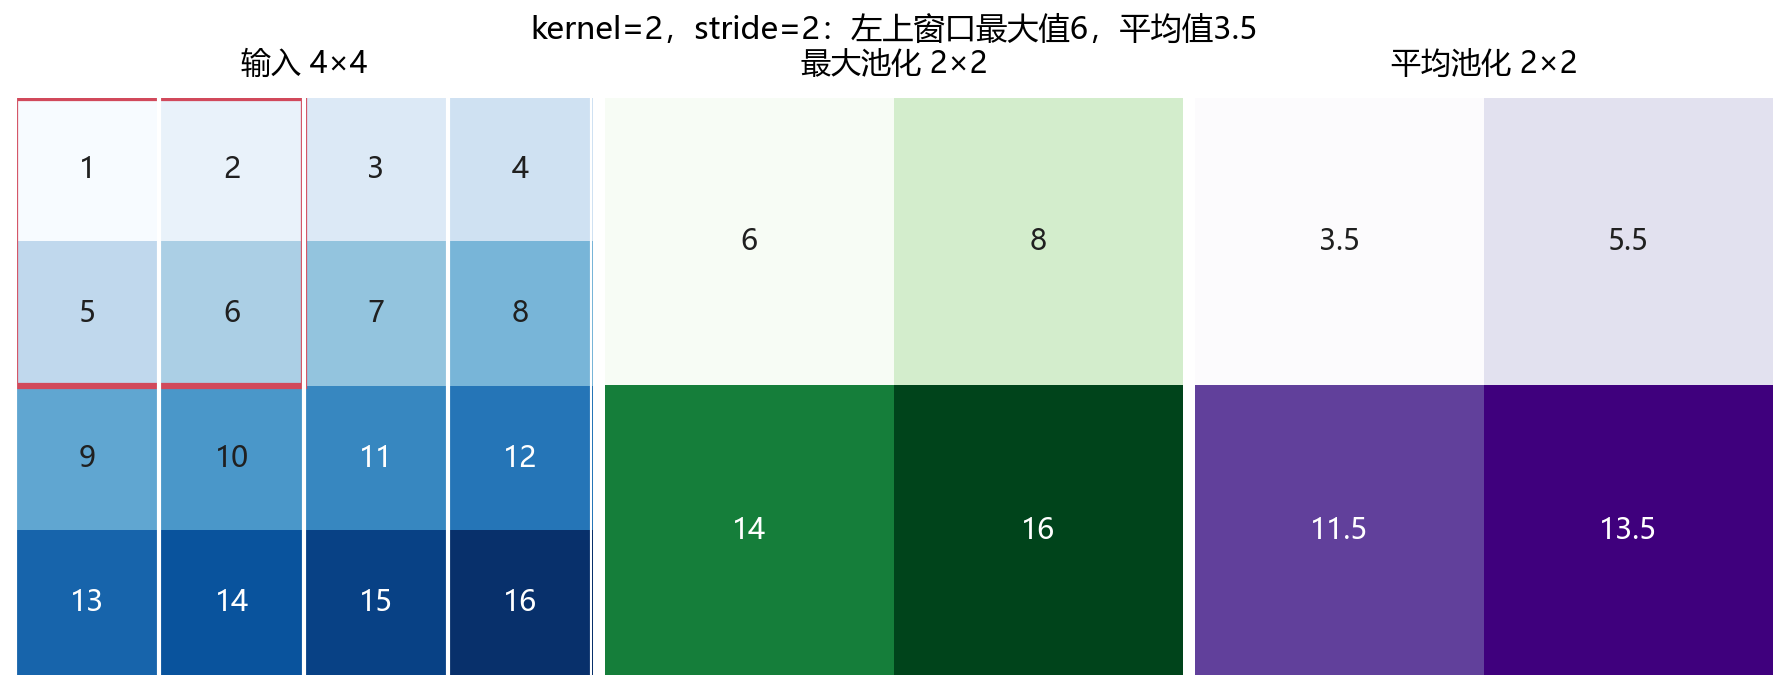

普通池化分别处理各通道，通常改变高宽而保留N和C。`nn.MaxPool2d(2)`省略stride时默认使用kernel_size，不能把这个默认值与Conv2d默认stride=1混淆。


## 22. 池化边界、尺寸与反向传播

MaxPool的边界padding按负无穷的含义处理，不是补0再取最大值。AvgPool的 `count_include_pad` 决定平均值的分母是否包含补零位置。

```python
negative_input = -torch.ones(1, 1, 2, 2)
negative_pooled = F.max_pool2d(negative_input, kernel_size=3, padding=1, stride=1)
assert torch.equal(negative_pooled, negative_input)

small_image = torch.arange(1, 10, dtype=torch.float32).reshape(1, 1, 3, 3)
include_pad = F.avg_pool2d(small_image, kernel_size=3, stride=1, padding=1, count_include_pad=True)
exclude_pad = F.avg_pool2d(small_image, kernel_size=3, stride=1, padding=1, count_include_pad=False)
assert abs(include_pad[0, 0, 0, 0].item() - 12 / 9) < 1e-6
assert exclude_pad[0, 0, 0, 0].item() == 12 / 4

pool_grad_input = pool_input.clone().requires_grad_()
F.max_pool2d(pool_grad_input, 2, 2).sum().backward()
expected_mask = torch.zeros_like(pool_grad_input)
expected_mask[:, :, 1::2, 1::2] = 1
assert torch.equal(pool_grad_input.grad, expected_mask)

avg_grad_input = pool_input.clone().requires_grad_()
F.avg_pool2d(avg_grad_input, 2, 2).sum().backward()
assert torch.equal(avg_grad_input.grad, torch.full_like(avg_grad_input, 0.25))
```

默认 `ceil_mode=False` 的MaxPool尺寸可按17节的公式计算，dilation取池化层配置；AvgPool没有dilation参数，可按D=1理解。启用 `ceil_mode=True` 时有向上取整和边界窗口规则，需要按接口单独核对。本例最大值均唯一，因此梯度清楚落在每个窗口最大值位置。


## 23. 连接成一个CNN骨架：从特征图到分类logits

用AdaptiveAvgPool把每个通道汇总为1×1，再展平和分类，可避免为每个输入分辨率手写Flatten维度。它不意味着任意小图都能输入，前面的卷积和池化仍有尺寸要求。

```python
class TinyCNN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Linear(16, num_classes)

    def forward(self, x):
        return self.classifier(torch.flatten(self.features(x), start_dim=1))

tiny_cnn = TinyCNN()
cnn_input = torch.randn(4, 3, 32, 32)
cnn_logits = tiny_cnn(cnn_input)
assert cnn_logits.shape == (4, 3)
assert tiny_cnn(torch.randn(4, 3, 48, 40)).shape == (4, 3)
cnn_loss = F.cross_entropy(cnn_logits, torch.tensor([0, 1, 2, 1]))
cnn_loss.backward()
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in tiny_cnn.parameters())
```

| 步骤 | `(N,C,H,W)`或矩阵shape |
| --- | --- |
| 输入 | `(4,3,32,32)` |
| Conv2d(3,8,3,padding=1) + ReLU | `(4,8,32,32)` |
| MaxPool2d(2) | `(4,8,16,16)` |
| Conv2d(8,16,3,padding=1) + ReLU | `(4,16,16,16)` |
| AdaptiveAvgPool2d(1) | `(4,16,1,1)` |
| Flatten(start_dim=1) | `(4,16)` |
| Linear(16,3) | `(4,3)` |

这里仅验证shape与梯度，随机输入并没有训练成图像分类模型。不能把这段骨架的随机预测当成识别能力；07篇再继续CNN实战。


## 24. 常见错误与排查

| 错误或现象 | 检查方向 |
| --- | --- |
| 交叉熵提示标签范围错误 | 类别编号必须位于0到C-1，不能直接把价格金额当类别ID |
| logits与标签batch数不一致 | 输入与标签是否同批、是否误用squeeze删掉batch维 |
| 评价时输出仍随机 | 整体模型是否调用eval；函数式Dropout是否传training |
| 加载后预测不同 | 结构、权重、预处理、列顺序与类别映射是否一致 |
| Conv2d提示输入通道错误 | 实际是HWC还是NCHW，RGB还是灰度，in_channels是否匹配 |
| Linear出现矩阵尺寸错误 | 逐层打印shape，检查池化后展平维度 |
| 图像颜色异常 | RGB/BGR是否混用，是否重复除以255 |
| 卷积后空间尺寸意外缩小 | 分别代入高宽，核对stride、padding、dilation |
| MaxPool能反传却没有参数 | 求导图与可训练参数是不同概念 |

调试时优先使用少量固定输入，核对标签、shape、dtype、数值范围和loss。模型训练问题与图像维度问题往往要从输入开始排查，不能只在最终层改数字。


## 25. 练习与参考答案

1. 输入为 `(8,3,32,32)`，经过 `Conv2d(3,6,5,padding=2)` 和 `MaxPool2d(2)`，再Flatten，最终shape和卷积参数量是多少？
2. 把15节卷积核右下角从2改成1，左上输出应该是多少？
3. 为什么不能先用全部数据拟合StandardScaler，再切分训练与测试？
4. 模型保存后，用同一批输入如何确认加载与预处理正确？
5. MaxPool没有参数，为什么仍能向前面的卷积传递梯度？

参考答案：

- 第1题：卷积为 `(8,6,32,32)`，池化为 `(8,6,16,16)`，Flatten为 `(8,1536)`。有偏置时卷积参数量为 `6*(3*5*5+1)=456`。
- 第2题：`1+6=7`，核不翻转。
- 第3题：全量均值与标准差包含测试分布信息，会影响训练输入，造成预处理泄漏。
- 第4题：固定eval模式，复用训练统计量和列顺序，对比原模型与加载后模型的logits或概率，误差应在合理数值容差内。
- 第5题：池化输出是输入的可求导运算结果，梯度可经选中位置传回；这不要求池化本身有可训练参数。


## 26. 速查

| 主题 | 关键结论 |
| --- | --- |
| 手机分类输入 | `(N,F)`，float32；标签`(N,)`，int64 |
| 多分类训练 | logits + CrossEntropyLoss，训练前不加Softmax |
| 数据划分 | train更新，val选择，test最终评价 |
| 模型保存 | 权重 + 配置 + 特征顺序 + 标签映射 + 预处理 |
| 图像常用数组 | HWC；PIL.size为宽、高 |
| Conv2d常用批输入 | NCHW |
| 权重shape | `(C_out,C_in/groups,K_H,K_W)` |
| 普通卷积参数量 | `C_out*(C_in*K_H*K_W + bias项)` |
| 空间输出尺寸 | `floor((I+2P-D*(K-1)-1)/S+1)` |
| MaxPool / AvgPool | 局部最大值 / 局部平均值，通常没有可训练参数 |
| 分类输出 | `(N,C)` logits；概率用于展示时再Softmax |

先把ANN训练链路跑通，再逐层检查CNN维度；两者共享同样的优化、评估和保存原则。


## 27. day06目录与来源范围

已核对的17个视频文件：

| 编号 | 视频标题内容 |
| --- | --- |
| 01 | ANN案例_手机价格分类_准备数据集(回顾) |
| 02 | ANN案例_手机价格分类_搭建神经网络 |
| 03 | ANN案例_手机价格分类_模型训练 |
| 04 | ANN案例_手机价格分类_模型测试 |
| 05 | ANN案例_手机价格分类_调优思路 |
| 06 | 图像相关知识介绍 |
| 07 | 上午内容回顾 |
| 08 | CNN概述介绍 |
| 09 | 卷积层_计算规则介绍 |
| 10 | 卷积层_填充(Padding)介绍 |
| 11 | 卷积层_步长(Stride)介绍 |
| 12 | 卷积层_多通道卷积计算 |
| 13 | 卷积层_多卷积核卷积计算 |
| 14 | 卷积层_特征图(FeatureMap)计算规则 |
| 15 | 卷积层_API介绍 |
| 16 | 池化层_介绍 |
| 17 | 池化层_API介绍 |

本篇依据上述目录组织学习内容，没有读取教师压缩包正文、课程代码和手机原始CSV，也未转录视频。ANN示例是人工数据上的独立教学实现；CNN图使用本篇代码的实际数值绘制。全部图片以Notebook attachments保存，不依赖外部图片文件。

可核对接口：[Conv2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html)、[MaxPool2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html)、[AvgPool2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.AvgPool2d.html)、[CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)。
